# 04 · OLS：从目标函数到 QR 分解，再到 `statsmodels`

**问题**：新西兰的季度通胀与（以新西兰元计的）油价变化有多大关联？

本 notebook 按八个部分组织：经济直觉 → 数学表述 → 推导 → 微型数值例子 → 库实现 → 真实数据 → 诊断与解释 → 练习。

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from scipy import linalg

from economic_lab.data import transforms as tf
from economic_lab.data.build import load_dataset
from economic_lab.econometrics.ols import condition_number, ols, solve_qr, solve_svd, wald_test
from economic_lab.econometrics.timeseries import acf, ljung_box
from economic_lab.visualization import SERIES, use_lab_style

use_lab_style()
q = load_dataset("quarterly")
DATA_KIND = q.attrs["data_kind"]
print("DATA KIND:", DATA_KIND.upper())

DATA KIND: REAL


## Part 1 · 经济直觉

油价通过几个渠道进入 CPI：

1. **直接渠道**：汽油、柴油等燃料直接属于 CPI 篮子（属于 *tradable* 部分），零售燃油价格几周内就会反映原油价格。
2. **间接渠道**：运输、航空、化肥、塑料等成本上升，经过数个季度传导到其他商品和服务价格。
3. **第二轮效应**：如果企业和家庭因此提高通胀预期，工资和价格设定会进一步变化 —— 这正是货币政策关心的部分。

本 notebook 只估计一个简单的线性关系：
$$\pi_t = \alpha + \beta\,\Delta o_t + \gamma\,\text{GST}_t + u_t,$$
$\pi_t$ 是季度环比 CPI 通胀（%），$\Delta o_t = 100\,\Delta\ln(\text{oil}^{NZD}_t)$ 是以新西兰元计油价的季度对数变化。
$\text{GST}_t$ 是消费税上调的虚拟变量（1989Q3 从 10% 升至 12.5%，2010Q4 升至 15%），它们产生了一次性的价格跳升，与油价无关。

**我们做了哪些假设？** 线性；关系在样本期内稳定；最重要的是 —— 解释变量与误差项不相关。
最后一个假设对油价 **并不显然成立**：全球需求旺盛时，油价上涨，新西兰的出口价格和需求也上升，通胀可能因此上升。
所以 $\beta$ 衡量的是 **统计关联**，而不是 "外生油价冲击的因果效应"。识别问题是 Track B 的主题。

## Part 2 · 数学表述

矩阵形式：$y = X\beta + u$

| 符号 | 维度 | 含义 |
|---|---|---|
| $y$ | $n\times 1$ | 被解释变量（通胀，%） |
| $X$ | $n\times k$ | 回归元矩阵，第一列为 1（常数项） |
| $\beta$ | $k\times 1$ | 未知系数 |
| $u$ | $n\times 1$ | 误差 |

经典假设：

* **A1 线性**：$y = X\beta+u$。
* **A2 满秩**：$\operatorname{rank}(X)=k$（没有完全共线性；例如样本中全为 0 的虚拟变量就违反 A2）。
* **A3 外生性**：$E[u\mid X]=0$。时间序列中，若包含 $y_{t-1}$，严格外生性必然不成立，此时依赖较弱的 $E[u_t\mid x_t]=0$ 和大样本理论。
* **A4 球形误差**：$\operatorname{Var}(u\mid X)=\sigma^2 I_n$（同方差、无序列相关）。时间序列中经常不成立 → HAC 标准误。
* **A5（可选）正态性**：$u\mid X\sim N(0,\sigma^2 I)$，使 t、F 统计量在小样本中精确成立。

## Part 3 · 推导

### 3.1 正规方程

最小化残差平方和：
$$S(\beta) = (y-X\beta)'(y-X\beta) = y'y - 2\beta'X'y + \beta'X'X\beta.$$
用矩阵求导法则 $\partial(\beta'a)/\partial\beta=a$，$\partial(\beta'A\beta)/\partial\beta=2A\beta$（$A$ 对称）：
$$\frac{\partial S}{\partial\beta} = -2X'y + 2X'X\beta = 0 \;\Longrightarrow\; X'X\hat\beta = X'y.$$
Hessian $2X'X$ 在 A2 下正定，所以这是唯一的最小值点：
$$\boxed{\hat\beta = (X'X)^{-1}X'y}$$

### 3.2 几何

定义 **帽子矩阵** $P = X(X'X)^{-1}X'$ 和残差生成矩阵 $M=I-P$。$\hat y = Py$ 是 $y$ 在 $X$ 列空间上的正交投影，$\hat u = My$。
正规方程等价于 $X'\hat u = 0$：残差与每一个回归元正交。有常数项时，这意味着残差之和为 0。

### 3.3 统计性质

代入 $y=X\beta+u$：$\hat\beta = \beta + (X'X)^{-1}X'u$。

* **无偏**（A1–A3）：$E[\hat\beta\mid X] = \beta$。
* **方差**（加上 A4）：$\operatorname{Var}(\hat\beta\mid X) = (X'X)^{-1}X'\,\sigma^2 I\,X(X'X)^{-1} = \sigma^2(X'X)^{-1}$。
* $\sigma^2$ 的无偏估计：$s^2 = \hat u'\hat u/(n-k)$（除以 $n-k$ 是因为 $\hat u$ 被约束在 $n-k$ 维空间中，$E[\hat u'\hat u]=\sigma^2\operatorname{tr}(M)=\sigma^2(n-k)$）。
* **Gauss-Markov 定理**：在 A1–A4 下，OLS 是最佳线性无偏估计量 (BLUE)。

### 3.4 当 A4 不成立：三明治 (sandwich) 估计量

一般地 $\operatorname{Var}(\hat\beta\mid X) = (X'X)^{-1}\,\underbrace{X'\Omega X}_{\text{meat}}\,(X'X)^{-1}$。
令得分 $g_t = x_t u_t$。Newey-West (1987) 估计长期方差：
$$\hat S = \hat\Gamma_0 + \sum_{l=1}^{L} w_l(\hat\Gamma_l+\hat\Gamma_l'),\qquad \hat\Gamma_l = \sum_{t=l+1}^{n} \hat g_t\hat g_{t-l}',\qquad w_l = 1-\frac{l}{L+1}.$$
Bartlett 权重 $w_l$ 保证 $\hat S$ 半正定。HAC 推断依赖大样本（使用正态分布临界值）。

### 3.5 数值计算：为什么不直接求逆？

条件数 $\kappa(X)=s_{\max}/s_{\min}$（奇异值之比）衡量对舍入误差的敏感度。关键事实：$\kappa(X'X)=\kappa(X)^2$。
双精度浮点约有 16 位有效数字；若 $\kappa(X)=10^6$，形成 $X'X$ 后约损失 12 位。

**QR 分解**：$X=QR$，$Q$ 为 $n\times k$ 正交列，$R$ 为 $k\times k$ 上三角。因为 $Q$ 保持长度，
$$\|y-X\beta\|^2 = \|Q'y - R\beta\|^2 + \text{const}\;\Rightarrow\; R\hat\beta = Q'y,$$
用回代法求解，只涉及 $\kappa(R)=\kappa(X)$。**SVD**：$X=U\Sigma V'$，$\hat\beta = V\Sigma^{-1}U'y$；
把很小的奇异值截断可以处理秩亏缺 —— 这就是 `np.linalg.lstsq` 的做法。`statsmodels` 默认使用伪逆 (pinv，基于 SVD)。

| 方法 | 代码 | 数值稳定性 |
|---|---|---|
| 显式求逆 | `inv(X.T@X) @ X.T @ y` | 最差，仅用于教学 |
| 正规方程 + Cholesky | `cho_solve(cho_factor(X.T@X), X.T@y)` | 快，但条件数被平方 |
| QR | `solve_triangular(R, Q.T@y)` | 好，本项目默认 |
| SVD / lstsq | `np.linalg.lstsq` | 最稳健，可处理秩亏缺 |

## Part 4 · 微型数值例子（8 个观测）

一个虚构的小样本：油价变化 $x$（%）与通胀 $y$（%）。一步步计算。

In [2]:
x = np.array([-10.0, 5.0, 20.0, -3.0, 8.0, 0.0, 15.0, -6.0])
y = np.array([0.2, 0.6, 1.0, 0.5, 0.7, 0.4, 0.9, 0.3])
n = len(y)
X = np.column_stack([np.ones(n), x])          # (8, 2)
print("X shape:", X.shape)

XtX = X.T @ X                                 # (2, 2)
Xty = X.T @ y                                 # (2,)
print("X'X =\n", XtX, "\nX'y =", Xty)

beta_hat = np.linalg.solve(XtX, Xty)          # solve X'X b = X'y without forming the inverse
print("beta_hat =", beta_hat.round(5))

# Simple regression shortcut: slope = cov(x, y) / var(x)
slope = np.cov(x, y, ddof=1)[0, 1] / np.var(x, ddof=1)
print("cov/var slope =", round(slope, 5), " intercept =", round(y.mean() - slope * x.mean(), 5))

X shape: (8, 2)
X'X =
 [[  8.  29.]
 [ 29. 859.]] 
X'y = [ 4.6 36.8]
beta_hat = [0.47823 0.0267 ]
cov/var slope = 0.0267  intercept = 0.47823


In [3]:
u_hat = y - X @ beta_hat
print("residuals:", u_hat.round(4))
print("X'u_hat (should be ~0):", (X.T @ u_hat).round(12))

k = X.shape[1]
s2 = u_hat @ u_hat / (n - k)
cov_beta = s2 * np.linalg.inv(XtX)
se = np.sqrt(np.diag(cov_beta))
print(f"s^2 = {s2:.5f}, se = {se.round(5)}, t = {(beta_hat / se).round(3)}")

# Same numbers through QR and SVD
print("QR :", solve_qr(X, y).round(5))
print("SVD:", solve_svd(X, y).round(5))

# Projection geometry: P is symmetric, idempotent and has trace k
P = X @ np.linalg.solve(XtX, X.T)
print("P symmetric:", np.allclose(P, P.T), "| idempotent:", np.allclose(P @ P, P), "| trace:", round(np.trace(P), 6))

residuals: [-0.0113 -0.0117 -0.0121  0.1019  0.0082 -0.0782  0.0213 -0.0181]
X'u_hat (should be ~0): [-0. -0.]
s^2 = 0.00296, se = [0.02053 0.00198], t = [23.294 13.474]
QR : [0.47823 0.0267 ]
SVD: [0.47823 0.0267 ]
P symmetric: True | idempotent: True | trace: 2.0


解读：斜率约 0.03 —— 在这个虚构的例子里，油价每上涨 1%，当季通胀高约 0.03 个百分点。

## Part 5 · 库实现与对照

### 5.1 我们的 `ols()` vs `statsmodels.OLS`

In [4]:
ours = ols(y, X)
ref = sm.OLS(y, X).fit()
comparison = pd.DataFrame({
    "ours_coef": ours.params.to_numpy(), "sm_coef": ref.params,
    "ours_se": ours.bse.to_numpy(), "sm_se": ref.bse,
    "ours_p": ours.pvalues.to_numpy(), "sm_p": ref.pvalues,
}, index=["const", "x"])
print(comparison)
print("max |difference| in coefficients:", np.abs(comparison.ours_coef - comparison.sm_coef).max())

       ours_coef   sm_coef   ours_se     sm_se        ours_p          sm_p
const   0.478229  0.478229  0.020530  0.020530  4.104537e-07  4.104537e-07
x       0.026695  0.026695  0.001981  0.001981  1.035639e-05  1.035639e-05
max |difference| in coefficients: 5.551115123125783e-17


差异在 $10^{-15}$ 量级 —— 浮点舍入误差，来自不同的算法路径（我们用 QR，statsmodels 用 SVD 伪逆）。

### 5.2 数值稳定性实验

多项式回归 $y = \sum_{j=0}^{9}t^j$ 的设计矩阵（Vandermonde 矩阵）是出了名的病态。真值 $\beta_j=1$：

In [5]:
t = np.linspace(0, 1, 100)
V = np.vander(t, 10, increasing=True)
yv = V @ np.ones(10)
print(f"kappa(X)   = {condition_number(V):.2e}")
print(f"kappa(X'X) = {condition_number(V.T @ V):.2e}")
errors = {m: np.abs(ols(yv, V, method=m).params.to_numpy() - 1).max()
          for m in ["inverse", "normal", "qr", "svd", "lstsq"]}
pd.Series(errors, name="max |beta_hat - 1|").map("{:.2e}".format)

kappa(X)   = 3.72e+06
kappa(X'X) = 1.38e+13


inverse    3.72e-03
normal     1.23e-04
qr         1.47e-10
svd        3.15e-10
lstsq      2.38e-10
Name: max |beta_hat - 1|, dtype: str

即使数据 **完全没有噪声**，显式求逆也会产生明显误差，而 QR/SVD 接近机器精度。

### 5.3 交互：共线性如何放大标准误

设 $x_2 = x_1 + \text{noise}\cdot\eta$。噪声越小，$x_1$ 和 $x_2$ 越接近完全共线。方差膨胀因子 $\text{VIF}_j = 1/(1-R_j^2)$
（$R_j^2$ 是 $x_j$ 对其他回归元回归的 R²）告诉你 $\operatorname{Var}(\hat\beta_j)$ 比回归元正交时大多少倍。

In [6]:
def collinearity_demo(noise=0.3, n=100, seed=0):
    r = np.random.default_rng(seed)
    x1 = r.standard_normal(n)
    x2 = x1 + noise * r.standard_normal(n)
    Xc = np.column_stack([np.ones(n), x1, x2])
    yc = 1 + 0.5 * x1 + 0.5 * x2 + r.standard_normal(n)
    res = ols(yc, Xc)
    r2 = ols(x1, np.column_stack([np.ones(n), x2])).rsquared
    print(f"noise={noise:.3f}  corr(x1,x2)={np.corrcoef(x1, x2)[0, 1]:.4f}  kappa={condition_number(Xc):.1f}  VIF={1 / (1 - r2):.1f}")
    print(res.summary_frame().round(3))

try:
    from ipywidgets import FloatLogSlider, interact
    interact(collinearity_demo, noise=FloatLogSlider(value=0.3, base=10, min=-3, max=0.5, step=0.1),
             n=(30, 1000, 10), seed=(0, 20))
except ImportError:
    for nz in (1.0, 0.1, 0.01):
        collinearity_demo(nz)

noise=1.000  corr(x1,x2)=0.7286  kappa=2.8  VIF=2.1
     coef  std_err      t  p_value
x0  0.865    0.114  7.604    0.000
x1  0.446    0.172  2.594    0.011
x2  0.537    0.119  4.524    0.000
noise=0.100  corr(x1,x2)=0.9952  kappa=20.5  VIF=103.8
     coef  std_err      t  p_value
x0  0.865    0.114  7.604    0.000
x1  0.115    1.199  0.096    0.924
x2  0.867    1.186  0.731    0.467
noise=0.010  corr(x1,x2)=1.0000  kappa=203.3  VIF=10178.4
     coef  std_err      t  p_value
x0  0.865    0.114  7.604    0.000
x1 -3.187   11.870 -0.268    0.789
x2  4.169   11.863  0.351    0.726


注意：即使共线性很强，$\hat\beta_1+\hat\beta_2$ 仍然被精确估计 —— 共线性让我们分不清 *哪个* 变量起作用，但不影响它们的 *合计* 效应。

## Part 6 · 真实数据：新西兰通胀与油价

In [7]:
SAMPLE_START = "1992-01-01"
df = pd.DataFrame({
    "pi": tf.pct_change(q["cpi"], 1),
    "doil": tf.log_diff(q["oil_nzd"], 1),
    "doil_usd": tf.log_diff(q["brent_usd"], 1),
    "dfx": tf.log_diff(q["nzd_usd"], 1),
}).dropna().loc[SAMPLE_START:]
df["gst"] = 0.0
df.loc[df.index.isin(pd.to_datetime(["1989-07-01", "2010-10-01"])), "gst"] = 1.0
print(f"{DATA_KIND} data: {len(df)} quarters, {df.index[0].year}Q{df.index[0].quarter} to {df.index[-1].year}Q{df.index[-1].quarter}")
print(df.describe().round(3))

def design(frame, cols):
    # Constant + regressors; drop dummies that never switch on in this sample (they would break A2).
    Xd = pd.concat([pd.Series(1.0, index=frame.index, name="const"), frame[cols]], axis=1)
    return Xd.loc[:, (Xd.std() > 0) | (Xd.columns == "const")]

real data: 138 quarters, 1992Q1 to 2026Q2
            pi     doil  doil_usd      dfx      gst
count  138.000  138.000   138.000  138.000  138.000
mean     0.593    1.138     1.169    0.031    0.007
std      0.545   14.031    15.265    4.636    0.085
min     -0.876  -53.236   -73.854  -20.941    0.000
25%      0.305   -6.393    -7.378   -2.760    0.000
50%      0.509    1.844     2.037   -0.027    0.000
75%      0.900    8.767     9.031    3.054    0.000
max      2.318   32.100    38.128   12.457    1.000


In [8]:
X1 = design(df, ["doil", "gst"])
static_nr = ols(df["pi"], X1)
static_hac = ols(df["pi"], X1, cov_type="HAC", hac_lags=4)
table = pd.DataFrame({
    "coef": static_hac.params,
    "se_nonrobust": static_nr.bse,
    "se_HAC(4)": static_hac.bse,
    "p_HAC": static_hac.pvalues,
})
print(table.round(4))
print(f"R^2 = {static_hac.rsquared:.3f}, n = {static_hac.nobs}")

ref = sm.OLS(df["pi"], X1).fit(cov_type="HAC", cov_kwds={"maxlags": 4})
print("max |se diff| vs statsmodels HAC:", float(np.abs(ref.bse - static_hac.bse).max()))

         coef  se_nonrobust  se_HAC(4)  p_HAC
const  0.5615        0.0401     0.0621    0.0
doil   0.0174        0.0028     0.0030    0.0
gst    1.6416        0.4697     0.0699    0.0
R^2 = 0.275, n = 138
max |se diff| vs statsmodels HAC: 6.938893903907228e-17


A 10% rise in the NZD oil price is associated with 0.17 pp higher q/q CPI inflation in the same quarter (95% CI 0.12 to 0.23).


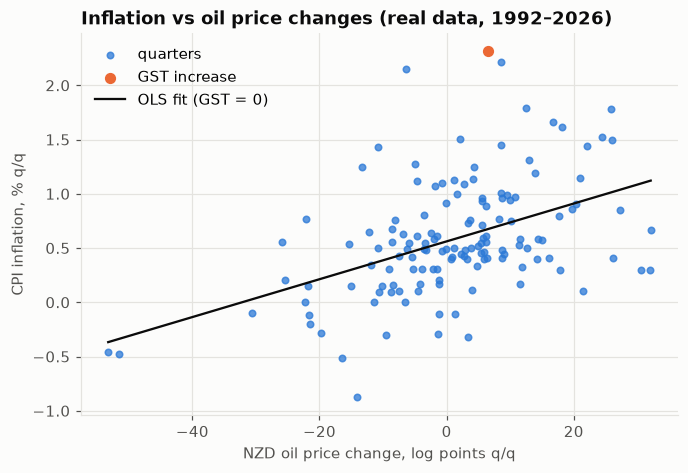

In [9]:
b = static_hac.params["doil"]
lo, hi = b - 1.96 * static_hac.bse["doil"], b + 1.96 * static_hac.bse["doil"]
print(f"A 10% rise in the NZD oil price is associated with {10 * b:.2f} pp higher q/q CPI inflation "
      f"in the same quarter (95% CI {10 * lo:.2f} to {10 * hi:.2f}).")
if DATA_KIND == "synthetic":
    p = q.attrs["true_params"]
    print(f"[synthetic] true contemporaneous effect on headline = w_T*b0 = {p['w_T'] * p['b0']:.4f}")

fig, ax = plt.subplots(figsize=(7, 4.5))
mask = df["gst"] == 0
ax.scatter(df.loc[mask, "doil"], df.loc[mask, "pi"], s=18, color=SERIES[0], alpha=0.75, label="quarters")
ax.scatter(df.loc[~mask, "doil"], df.loc[~mask, "pi"], s=40, color=SERIES[1], label="GST increase")
grid = np.linspace(df["doil"].min(), df["doil"].max(), 50)
ax.plot(grid, static_hac.params["const"] + b * grid, color="#0b0b0b", linewidth=1.5, label="OLS fit (GST = 0)")
ax.set_xlabel("NZD oil price change, log points q/q")
ax.set_ylabel("CPI inflation, % q/q")
ax.set_title(f"Inflation vs oil price changes ({DATA_KIND} data, {df.index[0].year}–{df.index[-1].year})")
ax.legend()
plt.show()

### 6.2 把油价拆成美元油价和汇率

由 $\Delta o_t = \Delta o^{USD}_t - \Delta e_t$（$e$ = log NZDUSD），上面的回归隐含约束：美元油价的系数 = −汇率的系数。放松这个约束：
$$\pi_t = \alpha + \beta_1\Delta o^{USD}_t + \beta_2\Delta e_t + \gamma\,\text{GST}_t + u_t,$$
再用 Wald 检验 $H_0:\beta_1+\beta_2=0$。汇率影响 **所有** 进口商品，所以 $|\beta_2|$ 可能大于 $\beta_1$。

In [10]:
X2 = design(df, ["doil_usd", "dfx", "gst"])
split = ols(df["pi"], X2, cov_type="HAC", hac_lags=4)
print(split.summary_frame().round(4))
names = list(split.params.index)
R = np.zeros((1, len(names)))
R[0, names.index("doil_usd")] = 1
R[0, names.index("dfx")] = 1
w = wald_test(split, R)
print(f"\nH0: beta_usd + beta_fx = 0  ->  Wald = {w['wald']:.2f}, p = {w['p_chi2']:.3f}")

            coef  std_err        t  p_value
const     0.5610   0.0617   9.0888   0.0000
doil_usd  0.0179   0.0032   5.5825   0.0000
dfx      -0.0274   0.0107  -2.5593   0.0105
gst       1.6900   0.0599  28.2135   0.0000

H0: beta_usd + beta_fx = 0  ->  Wald = 1.13, p = 0.287


## Part 7 · 诊断与解释

### 7.1 残差自相关

residual ACF(1..4): [0.425 0.439 0.226 0.35 ]
Ljung-Box(8): {'Q': 92.72887, 'df': 8, 'p_value': 0.0}
Breusch-Pagan LM = 1.11, p = 0.573


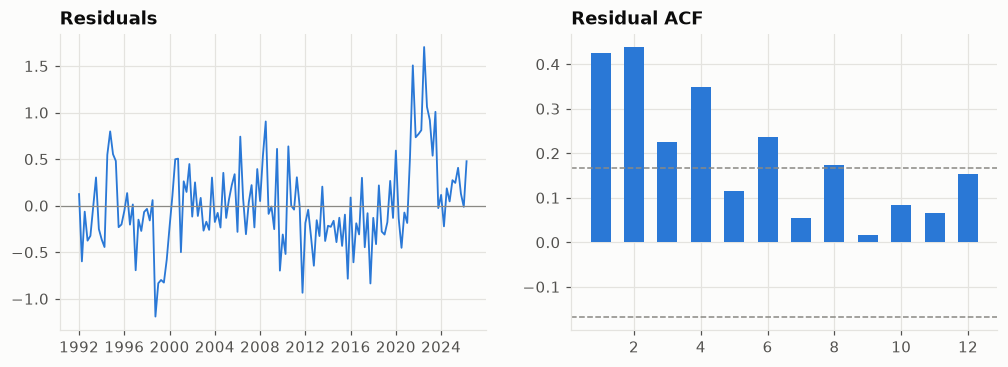

In [11]:
resid = static_hac.resid
print("residual ACF(1..4):", acf(resid, 4)[1:].round(3))
print("Ljung-Box(8):", {k: round(v, 5) for k, v in ljung_box(resid, 8).items()})

from statsmodels.stats.diagnostic import het_breuschpagan
bp = het_breuschpagan(resid, X1)
print(f"Breusch-Pagan LM = {bp[0]:.2f}, p = {bp[1]:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot(resid.index, resid, color=SERIES[0], linewidth=1.2)
axes[0].axhline(0, color="#8a8984", linewidth=0.8)
axes[0].set_title("Residuals")
axes[1].bar(range(1, 13), acf(resid, 12)[1:], color=SERIES[0], width=0.6)
band = 1.96 / np.sqrt(len(resid))
axes[1].axhline(band, color="#8a8984", linestyle="--", linewidth=1)
axes[1].axhline(-band, color="#8a8984", linestyle="--", linewidth=1)
axes[1].set_title("Residual ACF")
plt.show()

在真实数据中，残差有显著的正自相关（Ljung-Box 强烈拒绝白噪声）。含义：

1. **非稳健标准误是错的**；HAC 修正了推断。
2. 更重要的是：**动态设定有误**。通胀具有持续性，油价的影响也可能延迟几个季度。静态模型把这些都塞进了误差项。
   HAC 只修补了标准误，没有修补模型 —— 下一步是 ARDL（notebook 05）。

### 7.2 样本稳定性

In [12]:
rows = {}
for a, b_ in [("1992", "2007"), ("2008", "2026")]:
    sub = df.loc[a:b_]
    r = ols(sub["pi"], design(sub, ["doil", "gst"]), cov_type="HAC", hac_lags=4)
    rows[f"{a}–{sub.index[-1].year}"] = {"beta_doil": r.params["doil"], "se": r.bse["doil"], "n": r.nobs}
pd.DataFrame(rows).T.round(4)

,beta_doil,se,n
1992–2007,0.0161,0.0053,64.0
2008–2026,0.0184,0.0032,74.0


### 7.3 这个系数 *不* 意味着什么

* **不是因果效应**：$\Delta o_t$ 包含全球需求冲击、石油供给冲击、以及汇率变化。全球需求冲击可能同时推高油价和新西兰的通胀（通过出口收入），
  使 $\hat\beta$ 高估 "纯供给冲击" 的影响；反之，若 NZD 在全球繁荣时升值，又会部分抵消。符号和大小的偏差方向都不确定。
* **不是长期传导**：它只衡量 *同一季度* 的关联。滞后效应和通胀惯性需要动态模型。
* **季度平均的时间对齐**：$\Delta o_t$ 是季度平均油价的变化，季度后半段的油价变动部分体现在下一季度，这是一个机械的滞后来源。
* **总体 CPI vs tradable CPI**：燃油属于 tradable CPI。下载 RBNZ M1 后，可以把被解释变量换成 tradable 通胀，系数应该更大。

**面试版一句话**：*"在 1992–2025 年的季度数据中，以新西兰元计的油价每上涨 10%，同季度总体 CPI 环比通胀约高 0.17 个百分点（HAC 标准误下显著）；
这是一个条件相关，而不是识别后的油价供给冲击效应，残差的强自相关表明需要动态模型。"*（数字以你运行的真实数据输出为准。）

## Part 8 · 练习

1. **Easy** — 把 `SAMPLE_START` 改为 `"2000-01-01"`，重新估计静态回归。系数和 HAC 标准误如何变化？
2. **Intermediate** — 在静态回归中加入 3 个季度虚拟变量（CPI 未季调），并用 Wald 检验它们是否联合显著。
3. **Advanced** — Monte Carlo：生成 $x_t$ 和 $u_t$ 均为 AR(1)（$\phi=0.7$）、真实斜率为 0.5 的数据（n=120），
   比较非稳健与 HAC(4) 的 95% 置信区间的 **实际覆盖率**。哪一个更接近 95%？为什么 HAC 也达不到 95%？

## 参考答案

In [13]:
# Exercise 1
sub = df.loc["2000":]
r = ols(sub["pi"], design(sub, ["doil", "gst"]), cov_type="HAC", hac_lags=4)
print(r.summary_frame().round(4))

         coef  std_err        t  p_value
const  0.6137   0.0699   8.7760      0.0
doil   0.0193   0.0027   7.0755      0.0
gst    1.5772   0.0743  21.2261      0.0


In [14]:
# Exercise 2
dfs = df.copy()
for qq in (2, 3, 4):
    dfs[f"Q{qq}"] = (dfs.index.quarter == qq).astype(float)
r = ols(dfs["pi"], design(dfs, ["doil", "gst", "Q2", "Q3", "Q4"]), cov_type="HAC", hac_lags=4)
names = list(r.params.index)
R = np.zeros((3, len(names)))
for i, c in enumerate(["Q2", "Q3", "Q4"]):
    R[i, names.index(c)] = 1
print(r.summary_frame().round(4))
print("Joint test of seasonal dummies:", {k: round(v, 4) for k, v in wald_test(r, R).items()})

         coef  std_err        t  p_value
const  0.5070   0.0633   8.0072   0.0000
doil   0.0163   0.0031   5.3204   0.0000
gst    1.7552   0.1081  16.2333   0.0000
Q2     0.0459   0.0718   0.6396   0.5224
Q3     0.2274   0.0829   2.7436   0.0061
Q4    -0.0513   0.0928  -0.5533   0.5800
Joint test of seasonal dummies: {'wald': 10.4411, 'F': 3.4804, 'df': 3, 'p_chi2': 0.0152, 'p_F': 0.0178}


In [15]:
# Exercise 3
from economic_lab.econometrics.timeseries import simulate_ar1

def coverage(reps=1000, n=120, phi=0.7, beta=0.5, L=4):
    hits_nr = hits_hac = 0
    for i in range(reps):
        xs = simulate_ar1(n, phi, seed=10_000 + i)
        us = simulate_ar1(n, phi, seed=20_000 + i)
        Xs = np.column_stack([np.ones(n), xs])
        ys = Xs @ [0.0, beta] + us
        for cov_type, counter in (("nonrobust", "nr"), ("HAC", "hac")):
            res = ols(ys, Xs, cov_type=cov_type, hac_lags=L)
            inside = abs(res.params.iloc[1] - beta) < 1.96 * res.bse.iloc[1]
            if counter == "nr":
                hits_nr += inside
            else:
                hits_hac += inside
    return hits_nr / reps, hits_hac / reps

nr, hac = coverage()
print(f"coverage of nominal 95% CI: nonrobust {nr:.3f}, HAC(4) {hac:.3f}")

coverage of nominal 95% CI: nonrobust 0.757, HAC(4) 0.854


非稳健区间的覆盖率远低于 95%：当回归元和误差都正自相关时，$\operatorname{Var}(\hat\beta)$ 被低估。
HAC 显著改善，但在 n=120、持续性较强时仍低于 95%：Newey-West 估计量在有限样本中向下偏（截断滞后 L 太小、
Bartlett 权重收缩高阶自协方差），这也是 "fixed-b" 渐近理论和更大 L 的动机。